# Klasifikasi Multi-class: A7, A8, dan A9

Di sini aku bahas tiga dataset multi-class: A7 `01_iris_flower_classification`, A8 `iris`, dan A9 `IRIS`. Spoiler: ketiganya ternyata dataset Iris, jadi bagian terpenting notebook ini adalah mengecek seberapa beda mereka sebenarnya.

Definisi multi-class: satu kolom target dengan lebih dari dua kelas, dan tiap sampel hanya punya satu kelas (kelasnya saling meniadakan).

Untuk menjalankan, taruh `archive (7).zip`, `archive (8).zip`, dan `archive (9).zip` di folder yang sama dengan notebook ini, atau ubah `DATA_DIR`. CSV dibaca langsung dari zip.

Skor 1-5 di bawah adalah penilaianku sendiri, dan baseline-nya model default tanpa tuning, jadi cukup sebagai gambaran kasar.

In [1]:
import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

SOURCES = {
    "A7 iris": (7, "01_iris_flower_classification.csv"),
    "A8 iris": (8, "iris.csv"),
    "A9 IRIS": (9, "IRIS.csv"),
}
MC = list(SOURCES)

SEED = 42
# Folder tempat file zip berada. Bisa diubah, atau set environment variable DATA_DIR.
DATA_DIR = os.environ.get("DATA_DIR", ".")

def find_zip(n):
    # cocok dengan 'archive (4).zip', 'archive__4_.zip', dst., tapi tidak 'archive (14).zip'
    pat = re.compile(rf"archive\D*{n}\D*\.zip$", re.I)
    for f in sorted(os.listdir(DATA_DIR)):
        if pat.search(f):
            return os.path.join(DATA_DIR, f)
    raise FileNotFoundError(f"Zip arsip {n} tidak ditemukan di DATA_DIR={DATA_DIR!r}")

def read_from_zip(n, member):
    with zipfile.ZipFile(find_zip(n)) as z:
        with z.open(member) as f:
            return pd.read_csv(f)

data = {k: read_from_zip(n, m) for k, (n, m) in SOURCES.items()}
print({k: v.shape for k, v in data.items()})

{'A7 iris': (150, 5), 'A8 iris': (150, 5), 'A9 IRIS': (150, 5)}


## 1. Gambaran umum data

In [2]:
rows = []
for k, df in data.items():
    rows.append({"Dataset": k, "Baris": df.shape[0], "Kolom": df.shape[1],
                 "Nilai kosong": int(df.isna().sum().sum()), "Baris duplikat": int(df.duplicated().sum())})
pd.DataFrame(rows).set_index("Dataset")

,Baris,Kolom,Nilai kosong,Baris duplikat
Dataset,,,,
A7 iris,150,5,0,3
A8 iris,150,5,0,1
A9 IRIS,150,5,0,3


## 2. Target dan distribusi kelas

Targetnya `species` dengan tiga kelas (setosa, versicolor, virginica), ditambah 4 fitur numerik: panjang dan lebar sepal serta petal.

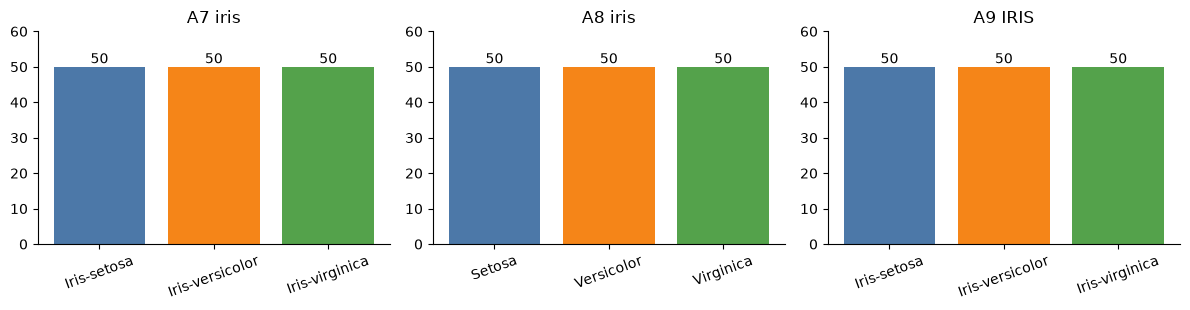

A7 iris -> kelas: 3 | duplikat baris: 3
A8 iris -> kelas: 3 | duplikat baris: 1
A9 IRIS -> kelas: 3 | duplikat baris: 3


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, k in zip(axs, MC):
    vc = data[k]["species"].value_counts()
    ax.bar(vc.index, vc.values, color=["#4C78A8", "#F58518", "#54A24B"])
    ax.set_title(k); ax.set_ylim(0, 60); ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(vc.values): ax.text(i, v + 1, str(v), ha="center")
plt.tight_layout(); plt.show()

for k in MC:
    print(k, "-> kelas:", data[k]["species"].nunique(), "| duplikat baris:", int(data[k].duplicated().sum()))

## 3. Seberapa beda ketiganya?

In [4]:
def norm(df):
    X = df.iloc[:, :4].reset_index(drop=True)
    y = df["species"].str.replace("Iris-", "", regex=False).str.lower().reset_index(drop=True)
    return X.values, y

X7, y7 = norm(data["A7 iris"]); X8, y8 = norm(data["A8 iris"]); X9, y9 = norm(data["A9 IRIS"])

print("A7 vs A9 -> fitur identik:", np.allclose(X7, X9), "| label identik:", bool((y7 == y9).all()))
beda = np.where(~np.isclose(X8, X9).all(axis=1))[0]
print("A8 vs A9 -> jumlah baris yang nilai fiturnya berbeda:", len(beda))
cmp = pd.concat({"A8": pd.DataFrame(X8[beda], index=beda), "A9": pd.DataFrame(X9[beda], index=beda)}, axis=1)
cmp.columns = [f"{a}_{b}" for a, b in cmp.columns]
display(cmp)

A7 vs A9 -> fitur identik: True | label identik: True
A8 vs A9 -> jumlah baris yang nilai fiturnya berbeda: 2


,A8_0,A8_1,A8_2,A8_3,A9_0,A9_1,A9_2,A9_3
34,4.9,3.1,1.5,0.2,4.9,3.1,1.5,0.1
37,4.9,3.6,1.4,0.1,4.9,3.1,1.5,0.1


Hasilnya: A7 dan A9 identik, bedanya cuma nama file dan nama kolom. A8 beda di dua baris saja (indeks 34 dan 37). Menurut catatan UCI, dua baris itu memang dikenal keliru di versi UCI, jadi kemungkinan A8 memakai versi yang sudah dikoreksi. Ini dugaanku saja dan belum aku cek ke sumber aslinya. Praktisnya, ketiganya adalah satu dataset yang sama.

## 4. Baseline model

Sama seperti sebelumnya: Logistic Regression dan Random Forest dengan 5-fold stratified cross-validation. Di bawahnya ada confusion matrix untuk A8.

Majority acc  Accuracy  Std acc  Macro-F1
Dataset Model                                                  
A7 iris LogReg               0.333     0.953    0.045     0.953
        RandomForest         0.333     0.960    0.039     0.960
A8 iris LogReg               0.333     0.953    0.045     0.953
        RandomForest         0.333     0.960    0.039     0.960
A9 IRIS LogReg               0.333     0.953    0.045     0.953
        RandomForest         0.333     0.960    0.039     0.960

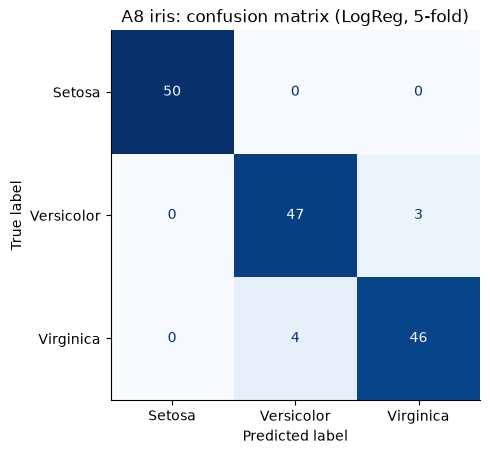

In [5]:
def cv_multiclass(key):
    df = data[key]; X = df.iloc[:, :4]; y = df["species"]
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    models = {"LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
              "RandomForest": RandomForestClassifier(200, random_state=SEED, n_jobs=-1)}
    out = []
    for name, m in models.items():
        r = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
        out.append({"Dataset": key, "Model": name,
                    "Majority acc": y.value_counts(normalize=True).max(),
                    "Accuracy": r["test_accuracy"].mean(), "Std acc": r["test_accuracy"].std(),
                    "Macro-F1": r["test_f1_macro"].mean()})
    return out

res_mc = pd.DataFrame([r for k in MC for r in cv_multiclass(k)]).set_index(["Dataset", "Model"])
display(res_mc.round(3))

# confusion matrix untuk A8 (versi yang kemungkinan terkoreksi)
df = data["A8 iris"]
pred = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                         df.iloc[:, :4], df["species"], cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
labels = sorted(df["species"].unique())
ConfusionMatrixDisplay(confusion_matrix(df["species"], pred, labels=labels), display_labels=labels).plot(cmap="Blues", colorbar=False)
plt.title("A8 iris: confusion matrix (LogReg, 5-fold)"); plt.show()

## 5. Apakah benar-benar multi-class?

In [6]:
verif = pd.DataFrame({
    k: {"Kolom target": "species", "Jumlah kelas": data[k]["species"].nunique(),
        "Label per sampel": 1,
        "Lolos (>2 kelas, 1 label/sampel)": data[k]["species"].nunique() > 2}
    for k in MC}).T
verif

,Kolom target,Jumlah kelas,Label per sampel,"Lolos (>2 kelas, 1 label/sampel)"
A7 iris,species,3,1,True
A8 iris,species,3,1,True
A9 IRIS,species,3,1,True


Ketiganya lolos: satu kolom target, tiga kelas yang saling eksklusif, dan seimbang sempurna (50:50:50).

| Dataset | Skor | Alasan |
|---|---|---|
| A7 iris | 5 | Multi-class klasik, tiga kelas eksklusif dan seimbang. Identik dengan A9. |
| A8 iris | 5 | Struktur sama, dan kemungkinan versi yang sudah dikoreksi (dua baris beda dari A7/A9). |
| A9 IRIS | 5 | Struktur sama. Identik dengan A7. |

In [7]:
SKOR = {"A7 iris": 5, "A8 iris": 5, "A9 IRIS": 5}
summary = pd.DataFrame({
    "Sampel": {k: len(data[k]) for k in MC},
    "Fitur input": {k: 4 for k in MC},
    "Kelas": {k: data[k]["species"].nunique() for k in MC},
    "Imbalance (max/min)": {k: 1.0 for k in MC},
    "Duplikat baris": {k: int(data[k].duplicated().sum()) for k in MC},
    "Macro-F1 (LogReg)": {k: round(res_mc.loc[(k, "LogReg"), "Macro-F1"], 3) for k in MC},
    "Skor kesesuaian": SKOR,
})
summary

,Sampel,Fitur input,Kelas,Imbalance (max/min),Duplikat baris,Macro-F1 (LogReg),Skor kesesuaian
A7 iris,150,4,3,1.0,3,0.953,5
A8 iris,150,4,3,1.0,1,0.953,5
A9 IRIS,150,4,3,1.0,3,0.953,5


## 6. Kesimpulan

Untuk mewakili multi-class aku pilih **A8 `iris`**. Secara struktur ketiganya sama-sama murni, tapi A8 kemungkinan memuat koreksi data, jadi aku anggap paling rapi. A7 dan A9 identik.

Yang perlu dipikirkan: karena ketiganya pada dasarnya satu dataset, membandingkan mereka satu sama lain hampir tidak ada gunanya. Hasil baseline-nya saja sama persis. Kalau tujuannya perbandingan yang adil, sebaiknya dua di antaranya diganti dataset multi-class lain, misalnya Wine, Digits, atau Penguins.

Soal pemodelan: neural network untuk multi-class biasanya memakai softmax dengan categorical cross-entropy, dan metrik yang cocok adalah macro atau weighted F1 plus confusion matrix. Iris seimbang dan hampir terpisah sempurna, jadi accuracy saja sudah cukup di sini, tapi itu tidak berlaku di data yang imbalanced.